# Programming Assignment Problem 2.2

In [4]:
# Let Tn(x) be the taylor polynomial of degree n for f(x) = ln(1 + x) at a = 0

import numpy as np

# Get the nest function from the other file. I just rewrote the nest function here.

def nest(c, x, a):
    # Last time I used reversed, but this time I am going to use the standard form
    # Initialize result
    n = len(c) - 1
    offset = x - a
    result = c[n]

    # Iterate through the list of coefficients and apply the Horner algorithm
    for coefficient in range(n-1, -1, -1):

        # Let the result be the result times the number plus the coefficient
        result = c[coefficient] + offset * result

    return result

## Part 1

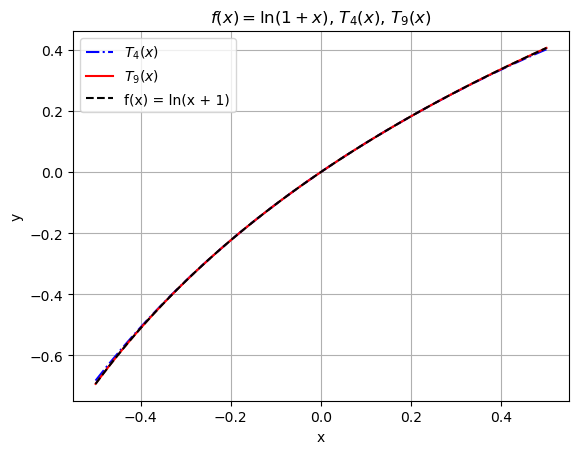

In [6]:
# 1) Plot f(x) for T4(x) and T9(x)

import matplotlib.pyplot as plt

# Let x be the linspace
x = np.linspace(-0.5,0.5,101)

# Get coefficients for T4 and T9
c4 = [0, 1, -1/2, 1/3, -1/4]

c9 = c4 + [1/5, -1/6, 1/7, -1/8, 1/9]

f = np.log(x + 1)

t4 = nest(c4, x, 0)
t9 = nest(c9, x, 0)

plt.plot(x, t4, 'b-.', label="$T_4(x)$")
plt.plot(x, t9, 'r-', label="$T_9(x)$")
plt.plot(x, f, 'k--', label="f(x) = ln(x + 1)")
plt.legend()
plt.title("$f(x) = \\ln(1 + x)$, $T_4(x)$, $T_9(x)$")
plt.grid(True)
plt.ylabel("y")
plt.xlabel("x")
plt.show()


## Part 2

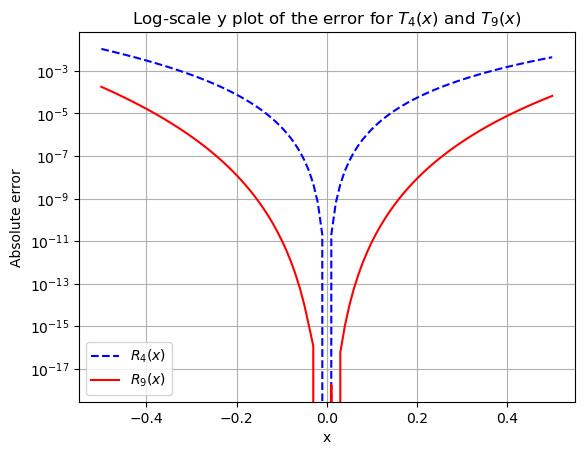

In [ ]:
# 2) Plot the Taylor's remainders (the error terms) |f(x)-T4(x)| and |f(x)-T9(x)|

err4 = np.abs(f - t4)
err9 = np.abs(f - t9)

plt.semilogy(x, err4, 'b--', label='$R_4(x)$')
plt.semilogy(x, err9, 'r-', label='$R_9(x)$')

plt.xlabel('x')
plt.ylabel('Absolute error')
plt.title('Log-scale y plot of the error for $T_4(x)$ and $T_9(x)$')
plt.legend()
plt.grid(True)
plt.show()

# Note the small R9(x) "residue" on the R4(x) curve on the positive side is due to roundoff error.

## Part 3

### Taylor's Theorem Error Bound

We must use Taylor's remainder

$$
R_n(x)
=
\frac{f^{(n+1)}(c)}{(n+1)!}(x-a)^{n+1},
$$

For $T_9(x)$, we use the 10th derivative. The pattern for the derivatives of ln(1 + x) is defined as:

$$
f^{(n)}(x)
=
(-1)^{n-1}\frac{(n-1)!}{(1+x)^n},
\qquad n\ge 1
$$

Plugging in the numbers:

$$
\left|f^{(10)}(c)\right|
=
\frac{9!}{(1+c)^{10}}.
$$

To find the largest worst-case upper bound on $[-0.5,0.5]$, plug in $c=-0.5$:

$$
\left|f^{(10)}(-0.5)\right|
=
\frac{9!}{(0.5)^{10}}.
$$

Thus,

$$
\left|R_9(x)\right|
\leq
\frac{9!}{10!(0.5)^{10}}(0.5)^{10}
=
0.1.
$$

Therefore, the upper bound is defined as:

$$
\boxed{|R_9(x)| \le 0.1}
$$

$$
\boxed{|\ln(1+x)-T_9(x)| < 0.1}
$$